# **Analyzing Marketing Campaign Data with Python**

**What do Data Analysts and Data Scientist on a Marketing Team do?**

* Analyzing Marketing **Campaign Performance**.

* Attributing Credit for **Conversions** to **Marketing Channels**.

* **Customer Segmentation** that leads to **Targetted Marketing Campaign**.

* **A/B Testing.**

**Importing the Python Libraries**

In [1]:
import pandas as pd
import numpy as np

**Importing Data using pandas**

Reading Data from a URL:

**Reading our Marketing Campaign csv File:**

Since we are working in Google Colab, either we need to upload the data into session storage or, we need to show the path of file in the Google Drive.

In [3]:
marketing = pd.read_csv("marketing_new.csv")
marketing

,user_id,date_served,marketing_channel,variant,converted,language_displayed,language_preferred,age_group,date_subscribed,date_canceled,subscribing_channel,is_retained,DoW,channel_code,is_correct_lang
0,a100000029,1/1/2018,House Ads,personalization,True,English,English,0-18 years,1/1/2018,NaN,House Ads,True,0.0,1.0,Yes
1,a100000030,1/1/2018,House Ads,personalization,True,English,English,19-24 years,1/1/2018,NaN,House Ads,True,0.0,1.0,Yes
2,a100000031,1/1/2018,House Ads,personalization,True,English,English,24-30 years,1/1/2018,NaN,House Ads,True,0.0,1.0,Yes
3,a100000032,1/1/2018,House Ads,personalization,True,English,English,30-36 years,1/1/2018,NaN,House Ads,True,0.0,1.0,Yes
4,a100000033,1/1/2018,House Ads,personalization,True,English,English,36-45 years,1/1/2018,NaN,House Ads,True,0.0,1.0,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10032,a100007290,1/17/2018,Email,control,True,German,German,45-55 years,1/17/2018,1/24/2018,Email,False,2.0,4.0,Yes
10033,a100007291,1/17/2018,Email,control,True,German,German,55+ years,1/17/2018,NaN,Email,True,2.0,4.0,Yes
10034,a100007292,1/5/2018,Instagram,control,False,German,German,55+ years,1/17/2018,NaN,Email,True,2.0,4.0,Yes
10035,a100007293,1/17/2018,Email,control,True,German,German,0-18 years,1/17/2018,NaN,Email,True,2.0,4.0,Yes


In [4]:
# Get summary information of the dataframe
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10037 entries, 0 to 10036
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              10037 non-null  object 
 1   date_served          10021 non-null  object 
 2   marketing_channel    10022 non-null  object 
 3   variant              10037 non-null  object 
 4   converted            10037 non-null  bool   
 5   language_displayed   10037 non-null  object 
 6   language_preferred   10037 non-null  object 
 7   age_group            10037 non-null  object 
 8   date_subscribed      1856 non-null   object 
 9   date_canceled        577 non-null    object 
 10  subscribing_channel  1856 non-null   object 
 11  is_retained          10037 non-null  bool   
 12  DoW                  1856 non-null   float64
 13  channel_code         1856 non-null   float64
 14  is_correct_lang      10037 non-null  object 
dtypes: bool(2), float64(2), object(11)
m

# **A/B testing for Marketing**

**What is A/B testing?**

A/B testing, also known as split testing, is a marketing experiment wherein you split your audience to test variations on a campaign and determine which performs better.

**Prior to running the test determine:**

*   What is the desired outcome of the test? What is our
hypothesis?
*   What is the metric we are trying to impact (i.e., page views,
conversions)?
*   Will we get enough traffic to our site to reach statistical
significance and make a decision in a timely manner?


**Testing allows us to understand marketing impact**

**Question:**
How long does a test need to run?

***Let's consider our A/B Test on Personalized Email.***

**Test Allocation:**

In [5]:
marketing['marketing_channel'].unique()

array(['House Ads', 'Push', 'Facebook', 'Instagram', 'Email', nan],
      dtype=object)

In [6]:
email = marketing[marketing['marketing_channel'] == 'Email']
email

,user_id,date_served,marketing_channel,variant,converted,language_displayed,language_preferred,age_group,date_subscribed,date_canceled,subscribing_channel,is_retained,DoW,channel_code,is_correct_lang
354,a100000526,1/1/2018,Email,personalization,True,Arabic,Arabic,0-18 years,1/1/2018,NaN,Email,True,0.0,4.0,Yes
358,a100000530,1/5/2018,Email,personalization,True,Arabic,Arabic,19-24 years,1/5/2018,NaN,Email,True,4.0,4.0,Yes
362,a100000534,1/9/2018,Email,personalization,False,English,English,45-55 years,1/9/2018,NaN,Email,True,1.0,4.0,Yes
366,a100000538,1/13/2018,Email,personalization,True,Arabic,Arabic,24-30 years,1/13/2018,1/23/2018,Email,False,5.0,4.0,Yes
370,a100000542,1/17/2018,Email,personalization,True,English,English,0-18 years,1/17/2018,2/12/2018,Email,False,2.0,4.0,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10030,a100007288,1/17/2018,Email,control,True,German,German,30-36 years,1/17/2018,4/26/2018,Email,False,2.0,4.0,Yes
10031,a100007289,1/17/2018,Email,control,True,German,German,36-45 years,1/17/2018,1/27/2018,Email,False,2.0,4.0,Yes
10032,a100007290,1/17/2018,Email,control,True,German,German,45-55 years,1/17/2018,1/24/2018,Email,False,2.0,4.0,Yes
10033,a100007291,1/17/2018,Email,control,True,German,German,55+ years,1/17/2018,NaN,Email,True,2.0,4.0,Yes


In [7]:
alloc = email.groupby(['variant'])['user_id'].nunique()
alloc

variant
control            270
personalization    284
Name: user_id, dtype: int64

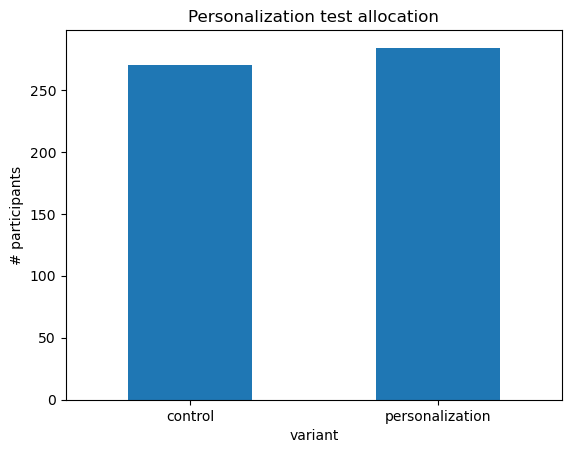

In [8]:
import matplotlib.pyplot as plt
alloc.plot(kind = 'bar')
plt.title('Personalization test allocation')
plt.ylabel('# participants')
plt.xticks(rotation = 0)
plt.show()

In [9]:
subscribers = email.groupby(['user_id', 'variant'])['converted'].max()
subscribers

user_id     variant        
a100000526  personalization     True
a100000530  personalization     True
a100000534  personalization    False
a100000538  personalization     True
a100000542  personalization     True
                               ...  
a100007288  control             True
a100007289  control             True
a100007290  control             True
a100007291  control             True
a100007293  control             True
Name: converted, Length: 554, dtype: bool

In [10]:
subscribers_df = pd.DataFrame(subscribers.unstack(level=1))
subscribers_df

variant,control,personalization
user_id,,
a100000526,NaN,True
a100000530,NaN,True
a100000534,NaN,False
a100000538,NaN,True
a100000542,NaN,True
...,...,...
a100007288,True,NaN
a100007289,True,NaN
a100007290,True,NaN


In [11]:
control = subscribers_df['control'].dropna()
control

user_id
a100000687    False
a100000688     True
a100000689     True
a100000690     True
a100000691     True
              ...  
a100007288     True
a100007289     True
a100007290     True
a100007291     True
a100007293     True
Name: control, Length: 270, dtype: object

In [12]:
# Drop missing values from the personalization column
personalization = subscribers_df['personalization'].dropna()
personalization

user_id
a100000526     True
a100000530     True
a100000534    False
a100000538     True
a100000542     True
              ...  
a100007273     True
a100007274     True
a100007275     True
a100007276     True
a100007277     True
Name: personalization, Length: 284, dtype: object

In [14]:
print('Control conversion rate:', np.mean(control))
print('Personalization conversion rate:', np.mean(personalization))

Control conversion rate: 0.2814814814814815
Personalization conversion rate: 0.3908450704225352


**T-test in Python**

In [15]:
control_numeric = control.astype(int)
personalization_numeric = personalization.astype(int)
control_numeric

user_id
a100000687    0
a100000688    1
a100000689    1
a100000690    1
a100000691    1
             ..
a100007288    1
a100007289    1
a100007290    1
a100007291    1
a100007293    1
Name: control, Length: 270, dtype: int32

In [17]:
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

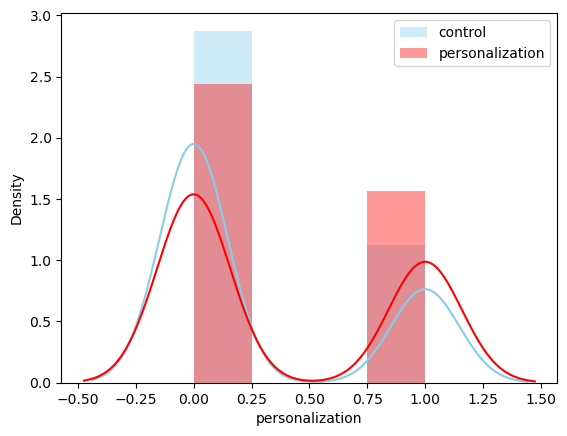

In [18]:
sns.distplot(control, color="skyblue", label="control")
sns.distplot(personalization, color="red", label="personalization")
plt.legend()
plt.show()

In [20]:
from scipy.stats import ttest_ind

In [22]:
t_statistic, p_value = ttest_ind(control_numeric, personalization_numeric)

In [23]:
print("t-statistic:", t_statistic)
print("p-value:", p_value)

t-statistic: -2.734329944750507
p-value: 0.006451487844694182


<b> Independent Samples t Test resulted as p < .05 which indicates that H0 is rejected. Accordingly there is a significant difference between convertion rate of control group and personalization Group